In [6]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns


In [7]:
df = pd.read_csv("smartcart_customers.csv")

In [8]:
df.shape 

(2240, 22)

In [9]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


## data preprocessing 

## 1. handle missing values 

In [11]:
df["Income"] = df["Income"].fillna(df["Income"].median())

In [12]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


## 2. feature engineering

In [13]:
#age

df["Age"] = 2026 - df["Year_Birth"]

In [14]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,88,88,3,8,10,4,7,0,1,69
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,1,6,2,1,1,2,5,0,0,72
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,21,42,1,8,2,10,4,0,0,61
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,3,5,2,2,0,4,6,0,0,42
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,27,15,5,5,3,6,5,0,0,45


In [16]:
#customer joining date 

df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"],dayfirst=True )

reference_date = df["Dt_Customer"].max()

df["customer_tenure_days"] = (reference_date - df["Dt_Customer"]).dt.days

In [17]:
df.head()


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,customer_tenure_days
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,88,3,8,10,4,7,0,1,69,663
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,6,2,1,1,2,5,0,0,72,113
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,42,1,8,2,10,4,0,0,61,312
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,5,2,2,0,4,6,0,0,42,139
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,15,5,5,3,6,5,0,0,45,161


In [19]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'customer_tenure_days'],
      dtype='object')

In [20]:
# spending 
df["total_spending"] = df["MntWines"]+df["MntFruits"]+df["MntMeatProducts"]+df["MntFishProducts"]+df["MntSweetProducts"]+df["MntGoldProds"]

In [23]:
# children 
df["total_children"] = df["Kidhome"] +df["Teenhome"]

In [26]:
# education 
df["Education"].value_counts()

df["Education"] = df["Education"].replace({
    "Basic":"undergraduate", "2n Cycle":"undergraduate",
    "Graduation" : "graduate",
    "Master":"postgraudate", "PhD":"postgraudate"
})

# undergrad, grad, postgrad 

In [27]:
df["Education"].value_counts()


Education
graduate         1127
postgraudate      856
undergraduate     257
Name: count, dtype: int64

In [29]:
df["Marital_Status"].value_counts()


Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

In [33]:
# marital status 
df["living_with"] = df["Marital_Status"].replace({
    "Married":"partner", "Together":"partner",
    "Single" : "alone","Alone":"alone",
    "Absurd": "alone","YOLO":"alone",
    "Divorced":"alone", "Widow":"alone"
})


In [34]:
df["living_with"].value_counts()


living_with
partner    1444
alone       796
Name: count, dtype: int64

## drop columns

In [35]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,customer_tenure_days,total_spending,total_children,living_with
0,5524,1957,graduate,Single,58138.0,0,0,2012-09-04,58,635,...,10,4,7,0,1,69,663,1617,0,alone
1,2174,1954,graduate,Single,46344.0,1,1,2014-03-08,38,11,...,1,2,5,0,0,72,113,27,2,alone
2,4141,1965,graduate,Together,71613.0,0,0,2013-08-21,26,426,...,2,10,4,0,0,61,312,776,0,partner
3,6182,1984,graduate,Together,26646.0,1,0,2014-02-10,26,11,...,0,4,6,0,0,42,139,53,1,partner
4,5324,1981,postgraudate,Married,58293.0,1,0,2014-01-19,94,173,...,3,6,5,0,0,45,161,422,1,partner


In [36]:
df.columns 

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'customer_tenure_days', 'total_spending',
       'total_children', 'living_with'],
      dtype='object')

In [37]:
cols = ["ID","Year_Birth","Marital_Status","Kidhome","Teenhome","Dt_Customer"]
spending_cols = ["MntWines","MntFruits","MntMeatProducts","MntFishProducts","MntSweetProducts","MntGoldProds"]

cols_to_del = cols + spending_cols

df_cleaned = df.drop(columns =cols_to_del )

In [39]:
df_cleaned.shape

(2240, 15)

## outliers 

In [ ]:
cols = ["Income","Recency","Age","total_spending","total_children"]

# relative plots of some features - pair plots

sns.pairplot(df_cleaned[cols])

In [41]:
print("data size with outliers",len(df_cleaned))

df_cleaned = df_cleaned[(df_cleaned["Age"]<90)]
df_cleaned = df_cleaned[(df_cleaned["Income"])<600_000]

print("data size after outliers",len(df_cleaned))

data size with outliers 2240
data size after outliers 2236


In [42]:
#heatmaps

corr = df_cleaned.corr(numeric_only=True)

<Axes: >

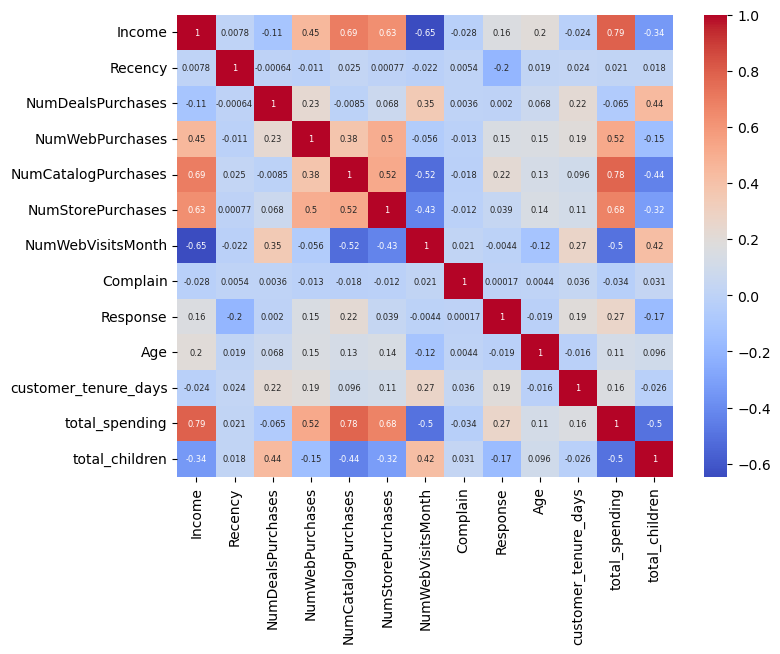

In [47]:
plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    annot=True,
    annot_kws={"size":6},
    cmap="coolwarm"
)

In [48]:
df_cleaned.shape

(2236, 15)

In [49]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,customer_tenure_days,total_spending,total_children,living_with
0,graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,alone
1,graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,alone
2,graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,partner
3,graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,partner
4,postgraudate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,partner


In [50]:
# encoding 

from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder()
cat_cols  = ["Education","living_with"]
enc_cols = ohe.fit_transform(df_cleaned[cat_cols])
enc_df = pd.DataFrame(enc_cols.toarray(),columns=ohe.get_feature_names_out(cat_cols),index = df_cleaned.index)

In [51]:
enc_df.head()

,Education_graduate,Education_postgraudate,Education_undergraduate,living_with_alone,living_with_partner
0,1.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,1.0


In [52]:
df_encoded = pd.concat([df_cleaned.drop(columns=cat_cols),enc_df],axis = 1)

In [53]:
df_encoded.shape

(2236, 18)

# scaling


In [54]:
from sklearn.preprocessing import StandardScaler

In [57]:
X = df_encoded

In [58]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## visualize

In [59]:
X_scaled.shape

(2236, 18)

In [60]:
# 2d 
from sklearn.decomposition import PCA

In [70]:
pca = PCA(n_components = 3)
X_pca = pca.fit_transform(X_scaled)

Text(0.5, 0.92, '3d projection')

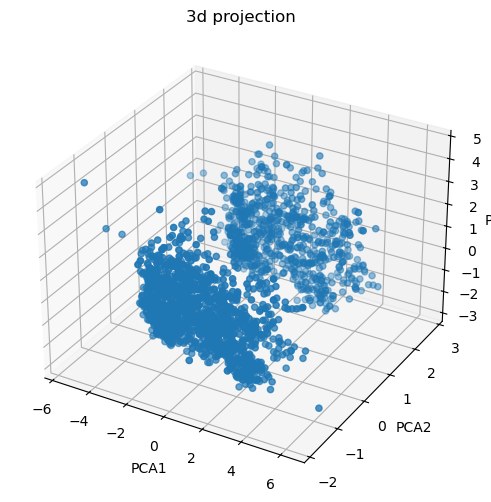

In [93]:
#plot
fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111,projection="3d")

ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2],)

ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("3d projection")

In [74]:
pca.explained_variance_ratio_

array([0.23163158, 0.11385454, 0.10405815])

## analyse K value 

# 1.elbow method 


In [76]:
from sklearn.cluster import KMeans 
from kneed import KneeLocator

wcss = []
for k in range(1,11):
    kmeans = KMeans(n_clusters =k,random_state= 42)
    kmeans.fit_predict(X_pca)
    wcss.append(kmeans.inertia_)
    

In [77]:
knee = KneeLocator(range(1,11),wcss,curve = "convex",direction="decreasing")
optimal_k = knee.elbow

In [79]:
print("best k = ",optimal_k)

best k =  4


Text(0, 0.5, 'wscc')

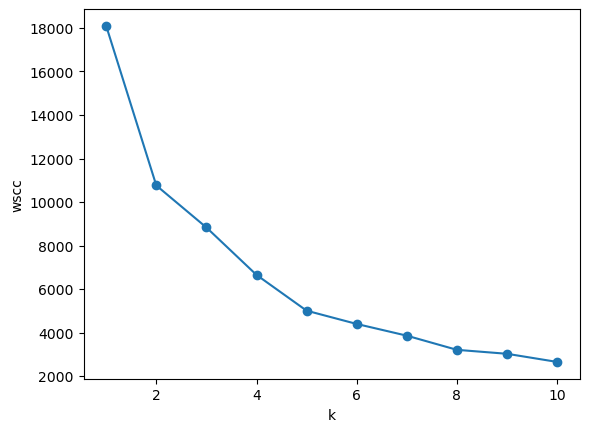

In [81]:
plt.plot(range(1,11),wcss,marker = "o")
plt.xlabel("k")
plt.ylabel("wscc")

# 2. silhouette score 

In [86]:
from sklearn.metrics import silhouette_score

scores = []
for k in range(2,11):
    kmeans  = KMeans(n_clusters=k, random_state = 42)
    labels = kmeans.fit_predict(X_pca)
    score = silhouette_score(X_pca,labels)
    scores.append(score)

Text(0, 0.5, 'silhouette_score')

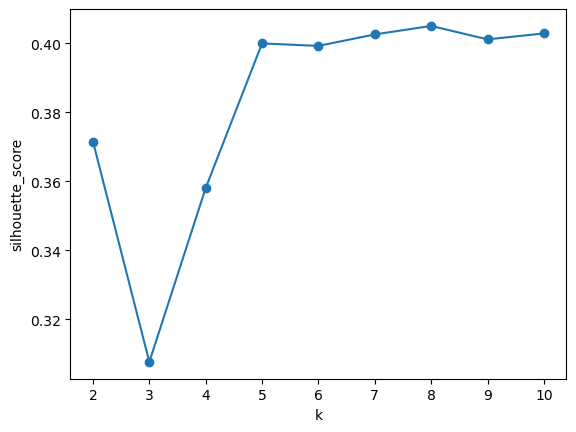

In [87]:
plt.plot(range(2,11),scores,marker = "o")
plt.xlabel("k")
plt.ylabel("silhouette_score")

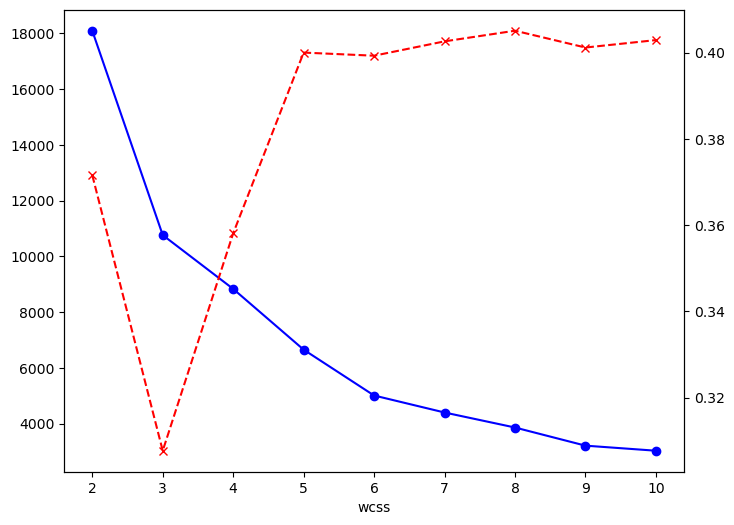

In [91]:
#combined plot 
k_range = range(2,11)

fig,ax1 = plt.subplots(figsize = (8,6))

ax1.plot(k_range,wcss[:len(k_range)],marker = 'o', color = "blue")
ax1.set_xlabel("k")
ax1.set_xlabel("wcss")

ax2 = ax1.twinx()
ax2.plot(k_range,scores[:len(k_range)],marker = 'x',color = "red",linestyle = "--")

# clustering 

In [94]:
kmeans = KMeans(n_clusters=4,random_state = 42)
labels_kmeans = kmeans.fit_predict(X_pca)

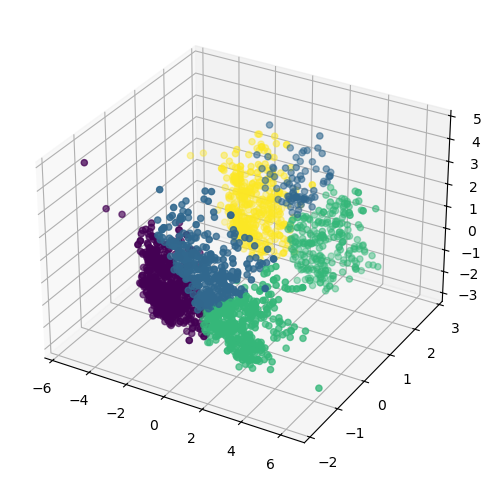

In [95]:
#plot
fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111,projection="3d")

ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2],c = labels_kmeans )


In [97]:
# Agglomerative Clustering
from sklearn.cluster import AgglomerativeClustering


In [99]:
agg_clf = AgglomerativeClustering(n_clusters=4,linkage="ward")
labels_agg = agg_clf.fit_predict(X_pca)

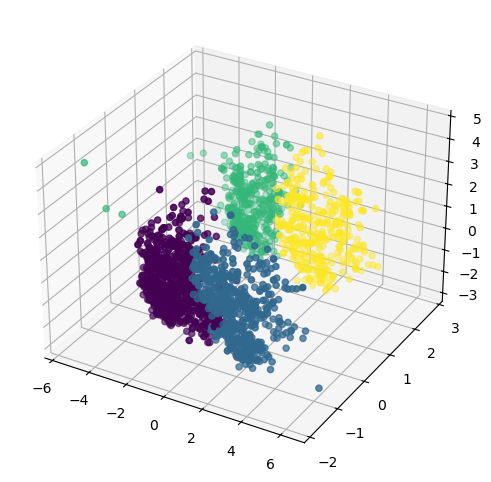

In [100]:
fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111,projection="3d")

ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2],c = labels_agg )


# characterization of clusters

In [113]:

X["cluster"] = labels_agg 

In [114]:
X.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,customer_tenure_days,total_spending,total_children,Education_graduate,Education_postgraudate,Education_undergraduate,living_with_alone,living_with_partner,cluster
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0,3
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0,2
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0,1
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0,0


<Axes: xlabel='cluster', ylabel='count'>

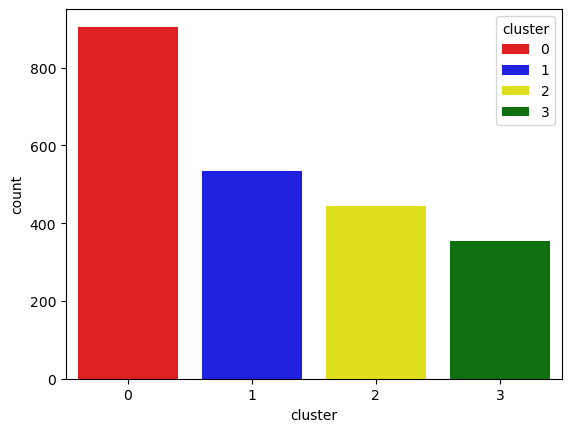

In [115]:
pal = ["red","blue","yellow","green"]

sns.countplot(x = X["cluster"],palette=pal,hue = X["cluster"])

<Axes: xlabel='total_spending', ylabel='Income'>

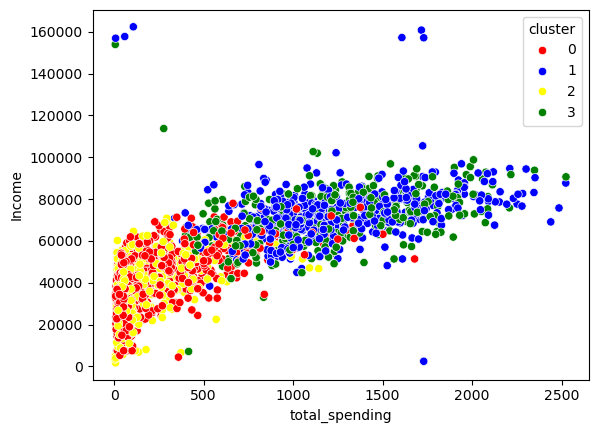

In [116]:
# income and spending patterns
sns.scatterplot(x=X["total_spending"],y = X["Income"],hue = X["cluster"],palette=pal)

In [117]:
# cluster summary 
cluster_summary = X.groupby("cluster").mean()
print(cluster_summary)

               Income    Recency  NumDealsPurchases  NumWebPurchases  \
cluster                                                                
0        39680.580110  48.914917           2.594475         3.153591   
1        72808.445693  49.202247           1.958801         5.687266   
2        36960.143018  48.319820           2.594595         2.713964   
3        70722.681303  50.504249           1.855524         5.790368   

         NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
cluster                                                                        
0                   0.969061           4.143646           6.307182  0.011050   
1                   5.498127           8.659176           3.580524  0.005618   
2                   0.837838           3.623874           6.659910  0.011261   
3                   5.014164           8.430595           3.728045  0.005666   

         Response        Age  customer_tenure_days  total_spending  \
cluster         